# Hydra - Does a wider ridge-regularisation grid help?

**Author:** Aarti

**Motivation.** The Hydra paper trains a ridge classifier but does not report the regularisation grid. The 30-resample reproduction (`aarti_hydra_reproduction_resamples.ipynb`) used the authors' README grid `np.logspace(-3, 3, 10)` (α from 0.001 to 1000), reproduced the published accuracies, and found the selected α at the **upper edge (1000) in 37 % of runs**, almost always on the harder datasets. That suggests the grid may be limiting the classifier. The QUANT × Hydra experiment found the same for ridge-based fusion (71–79 % of runs at the ceiling). Here we test it directly.

**Design.** Same 15 datasets, same 30 resamples (same splits, same Hydra seeds) as the reproduction notebook. For every (dataset, resample) the Hydra features are computed **once**, then three ridge classifiers are fitted that differ **only** in the α grid:

| Grid | α values | Note |
|---|---|---|
| `sklearn_default` | 0.1, 1, 10 | scikit-learn's `RidgeClassifierCV()` default |
| `readme` | 10^(−3 + 2i/3), i = 0…9  (= `np.logspace(-3, 3, 10)`) | authors' README; used in the reproduction and all other notebooks |
| `extended` | 10^(−3 + 2i/3), i = 0…14  (0.001 … ≈ 2.2·10⁶) | the README grid **plus** 5 larger values, same spacing |

Because `extended` contains every `readme` value, any accuracy difference between them is caused **only** by α > 1000 becoming available. Leave-one-out selection (`RidgeClassifierCV`'s default) picks α on the training set only, so the test set is never used for the choice.

**Checks built in.**
1. The `readme` results should reproduce the accuracies already saved in `results/reproduction/hydra_resample_runs.csv` (same code, splits and seeds).
2. Does the extended grid still hit *its* ceiling? If so, even larger α would be needed.

## Outputs (`results/Aarti/alpha_grid/`)
* `runs/` - one CSV per (dataset, resample) (resumable)
* `alpha_grid_runs.csv` - one row per (dataset, resample, grid)
* `alpha_grid_summary.csv`, `plots/`

### Cell 1 - Imports

In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util
import json
import os
import platform
import shutil
import sys
import traceback

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed

import aeon
import sklearn
from aeon.datasets import load_classification
from aeon.benchmarking.resampling import stratified_resample_data
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

### Cell 2 - Configuration, paths and grids

In [2]:
DATASETS = [   # the 15 datasets of aarti_hydra_reproduction_resamples.ipynb, same order
    "Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer",
    "Herring", "MiddlePhalanxTW", "Lightning2", "Lightning7", "Earthquakes",
    "MedicalImages", "Beef", "Adiac", "InsectWingbeatSound",
]
N_RESAMPLES = 30
N_WORKERS = 6
K, G = 8, 64
BATCH_SIZE = 256

GRIDS = {
    "sklearn_default": np.array([0.1, 1.0, 10.0]),
    "readme": 10.0 ** (-3 + (2 / 3) * np.arange(10)),
    "extended": 10.0 ** (-3 + (2 / 3) * np.arange(15)),
}
GRID_ORDER = list(GRIDS)
assert np.allclose(GRIDS["readme"], np.logspace(-3, 3, 10))
assert np.allclose(GRIDS["extended"][:10], GRIDS["readme"])

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (c for c in _candidates if (c / "hydra-authors-repo").is_dir() and (c / "results").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the hydra-time-series-project repository.")

HYDRA_SOURCE = PROJECT_ROOT / "hydra-authors-repo" / "code" / "hydra.py"
PAPER_RESULTS = PROJECT_ROOT / "hydra-authors-repo" / "results" / "results_ucr112_hydra.csv"
REPRO_RUNS = PROJECT_ROOT / "results" / "reproduction" / "hydra_resample_runs.csv"
DATA_DIR = PROJECT_ROOT / "data" / "ucr_tsml"
OUT_DIR = PROJECT_ROOT / "results" / "Aarti" / "alpha_grid"
TASK_DIR, PLOT_DIR = OUT_DIR / "runs", OUT_DIR / "plots"
for d in (DATA_DIR, TASK_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)

environment = {
    "python": sys.version.split()[0], "platform": platform.platform(), "processor": platform.processor(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    "pytorch": torch.__version__, "aeon": aeon.__version__,
    "threads_per_task": 1, "parallel_workers": N_WORKERS,
}
(OUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
print(f"{len(DATASETS)} datasets x {N_RESAMPLES} resamples = {len(DATASETS) * N_RESAMPLES} tasks")
for name, alphas in GRIDS.items():
    print(f"{name:16s} {len(alphas):2d} values: {alphas.min():.3g} ... {alphas.max():.3g}")

15 datasets x 30 resamples = 450 tasks
sklearn_default   3 values: 0.1 ... 10
readme           10 values: 0.001 ... 1e+03
extended         15 values: 0.001 ... 2.15e+06


### Cell 3 - Official Hydra, data loading and resampling

Identical to `aarti_hydra_reproduction_resamples.ipynb`, so resample *i* is the same split and the same Hydra kernels (seed = resample id).

In [3]:
def load_official_hydra():
    name = "hydra_official_impl"
    if name not in sys.modules:
        spec = importlib.util.spec_from_file_location(name, HYDRA_SOURCE)
        module = importlib.util.module_from_spec(spec)
        sys.modules[name] = module
        spec.loader.exec_module(module)
    return sys.modules[name].Hydra, sys.modules[name].SparseScaler


Hydra, SparseScaler = load_official_hydra()
import cloudpickle   # hydra.py is loaded from a file path: send it to worker processes by value
cloudpickle.register_pickle_by_value(sys.modules["hydra_official_impl"])

_default_splits = {}

def load_default_split(name):
    if name not in _default_splits:
        def _load():
            Xtr, ytr = load_classification(name, split="train", extract_path=str(DATA_DIR), return_metadata=False)
            Xte, yte = load_classification(name, split="test", extract_path=str(DATA_DIR), return_metadata=False)
            return Xtr, ytr, Xte, yte
        try:
            Xtr, ytr, Xte, yte = _load()
        except OSError as exc:   # truncated download -> delete cached copy, retry once
            print(f"{name}: could not parse cached files ({exc}); re-downloading.")
            shutil.rmtree(DATA_DIR / name, ignore_errors=True)
            Xtr, ytr, Xte, yte = _load()
        _default_splits[name] = (np.asarray(Xtr, dtype=np.float32), np.asarray(ytr).astype(str),
                                 np.asarray(Xte, dtype=np.float32), np.asarray(yte).astype(str))
    return _default_splits[name]


def get_resample(name, resample_id):
    Xtr, ytr, Xte, yte = load_default_split(name)
    if resample_id == 0:
        return Xtr, ytr, Xte, yte
    return stratified_resample_data(Xtr, ytr, Xte, yte, random_state=resample_id)


for name in DATASETS:   # download once, serially, before any parallel work
    load_default_split(name)
print("Loaded", len(DATASETS), "datasets")

Loaded 15 datasets


### Cell 4 - One task: Hydra features once, three ridge grids

For each grid we record the test accuracy, the selected α, and whether it is at the grid's lower or upper edge.

In [4]:
def run_task(name, resample):
    torch.set_num_threads(1)
    with threadpool_limits(limits=1):
        Xtr, ytr, Xte, yte = get_resample(name, resample)
        hydra = Hydra(Xtr.shape[-1], k=K, g=G, seed=resample)
        with torch.inference_mode():
            Ztr = hydra.batch(torch.as_tensor(np.ascontiguousarray(Xtr), dtype=torch.float32), batch_size=BATCH_SIZE)
            Zte = hydra.batch(torch.as_tensor(np.ascontiguousarray(Xte), dtype=torch.float32), batch_size=BATCH_SIZE)
        scaler = SparseScaler()
        Ztr = scaler.fit_transform(Ztr).numpy()
        Zte = scaler.transform(Zte).numpy()
        rows = []
        for grid, alphas in GRIDS.items():
            t = perf_counter()
            clf = RidgeClassifierCV(alphas=alphas).fit(Ztr, ytr)
            fit_s = perf_counter() - t
            pred = clf.predict(Zte)
            rows.append({
                "dataset": name, "resample": resample, "grid": grid,
                "n_train": len(ytr), "n_test": len(yte),
                "accuracy": accuracy_score(yte, pred),
                "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
                "ridge_alpha": clf.alpha_,
                "alpha_at_upper": bool(np.isclose(clf.alpha_, alphas.max())),
                "alpha_at_lower": bool(np.isclose(clf.alpha_, alphas.min())),
                "classifier_fit_seconds": fit_s,
            })
    return rows

smoke = pd.DataFrame(run_task("Coffee", 0))
display(smoke[["grid", "accuracy", "ridge_alpha", "alpha_at_upper", "alpha_at_lower"]])

,grid,accuracy,ridge_alpha,alpha_at_upper,alpha_at_lower
0,sklearn_default,1.0,0.100,False,True
1,readme,1.0,0.001,False,True
2,extended,1.0,0.001,False,True


### Cell 5 - Run all datasets × resamples (parallel, resumable)

One CSV per task in `results/Aarti/alpha_grid/runs/`; complete files are skipped on re-run.

In [5]:
def _task_file(d, r): return TASK_DIR / f"{d}__r{r:02d}.csv"

def _is_complete(d, r):
    try:
        return len(pd.read_csv(_task_file(d, r))) == len(GRIDS)
    except Exception:
        return False

def _run_and_save(d, r):
    try:
        rows = run_task(d, r)
    except Exception:
        return d, r, traceback.format_exc()
    pd.DataFrame(rows).to_csv(_task_file(d, r), index=False)
    return d, r, None

todo = [(d, r) for d in DATASETS for r in range(N_RESAMPLES) if not _is_complete(d, r)]
print(f"{len(todo)} of {len(DATASETS) * N_RESAMPLES} tasks to run")
if todo:
    wall = perf_counter()
    jobs = Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(delayed(_run_and_save)(d, r) for d, r in todo)
    for i, (d, r, err) in enumerate(jobs, 1):
        if err:
            print(f"FAILED {d} r{r}\n{err}")
        if i % 90 == 0 or i == len(todo):
            print(f"[{i:3d}/{len(todo)}] {(perf_counter() - wall) / 60:.1f} min elapsed")

runs = pd.concat([pd.read_csv(_task_file(d, r)) for d in DATASETS for r in range(N_RESAMPLES)], ignore_index=True)
runs.to_csv(OUT_DIR / "alpha_grid_runs.csv", index=False)
print("Rows:", len(runs))

0 of 450 tasks to run


Rows: 1350


### Cell 6 - Check: the `readme` grid reproduces the saved 30-resample runs

Same code, splits, seeds and grid as `aarti_hydra_reproduction_resamples.ipynb`, so the accuracies should match its saved runs (differences can only come from library-version floating-point effects).

In [6]:
repro = pd.read_csv(REPRO_RUNS)[["dataset", "resample", "accuracy", "ridge_alpha"]]
check = runs[runs.grid == "readme"].merge(repro, on=["dataset", "resample"], suffixes=("", "_repro"))
same_acc = np.isclose(check["accuracy"], check["accuracy_repro"])
same_alpha = np.isclose(check["ridge_alpha"], check["ridge_alpha_repro"])
print(f"Matched runs: {len(check)} / {len(DATASETS) * N_RESAMPLES}")
print(f"Identical accuracy: {same_acc.sum()} / {len(check)} ({same_acc.mean():.1%})")
print(f"Identical selected alpha: {same_alpha.sum()} / {len(check)} ({same_alpha.mean():.1%})")
print(f"Mean |accuracy difference|: {(check['accuracy'] - check['accuracy_repro']).abs().mean() * 100:.3f} pp")
if not same_acc.all():
    display(check.loc[~same_acc, ["dataset", "resample", "accuracy", "accuracy_repro", "ridge_alpha", "ridge_alpha_repro"]].head(10))

Matched runs: 450 / 450
Identical accuracy: 450 / 450 (100.0%)
Identical selected alpha: 449 / 450 (99.8%)
Mean |accuracy difference|: 0.000 pp


### Cell 7 - How often is α at the edge of each grid?

If the `extended` grid rarely hits its own ceiling, it is wide enough; if it still does, even larger α would be preferred.

In [7]:
edge = (runs.groupby(["dataset", "grid"])[["alpha_at_upper", "alpha_at_lower"]].mean() * 100).unstack("grid")
edge = edge.loc[DATASETS]
upper = edge["alpha_at_upper"][GRID_ORDER].add_prefix("% at upper: ")
lower = edge["alpha_at_lower"][GRID_ORDER].add_prefix("% at lower: ")
display(pd.concat([upper, lower], axis=1).round(1))

overall = runs.groupby("grid")[["alpha_at_upper", "alpha_at_lower"]].mean().loc[GRID_ORDER] * 100
print("Overall (% of runs):")
display(overall.round(1))

ext = runs[runs.grid == "extended"]
print(f"Extended grid: alpha > 1000 selected in {(ext.ridge_alpha > 1000 + 1e-9).mean():.1%} of runs")
display(ext.assign(log10_alpha=np.log10(ext.ridge_alpha)).groupby("dataset")["log10_alpha"]
        .describe()[["mean", "min", "50%", "max"]].loc[DATASETS].round(2)
        .rename(columns=lambda c: f"log10 alpha {c}"))

grid,% at upper: sklearn_default,% at upper: readme,% at upper: extended,% at lower: sklearn_default,% at lower: readme,% at lower: extended
dataset,,,,,,
Coffee,0.0,0.0,0.0,100.0,100.0,100.0
ECG200,60.0,23.3,0.0,40.0,40.0,40.0
GunPoint,0.0,0.0,0.0,100.0,100.0,100.0
ItalyPowerDemand,56.7,10.0,0.0,43.3,43.3,43.3
TwoLeadECG,0.0,0.0,0.0,100.0,100.0,100.0
Wafer,100.0,0.0,0.0,0.0,0.0,0.0
Herring,96.7,93.3,0.0,3.3,3.3,3.3
MiddlePhalanxTW,100.0,100.0,0.0,0.0,0.0,0.0
Lightning2,66.7,46.7,0.0,33.3,33.3,33.3


Overall (% of runs):


,alpha_at_upper,alpha_at_lower
grid,,
sklearn_default,63.3,36.7
readme,36.7,36.7
extended,0.0,36.7


Extended grid: alpha > 1000 selected in 22.2% of runs


,log10 alpha mean,log10 alpha min,log10 alpha 50%,log10 alpha max
dataset,,,,
Coffee,-3.00,-3.00,-3.00,-3.00
ECG200,0.22,-3.00,1.67,3.00
GunPoint,-3.00,-3.00,-3.00,-3.00
ItalyPowerDemand,-0.04,-3.00,1.67,3.00
TwoLeadECG,-3.00,-3.00,-3.00,-3.00
Wafer,2.04,1.00,2.33,2.33
Herring,3.67,-3.00,3.67,4.33
MiddlePhalanxTW,4.18,3.67,4.33,4.33
Lightning2,1.02,-3.00,2.33,3.67


### Cell 8 - Accuracy: does the wider grid help?

Per dataset: mean accuracy over 30 resamples for each grid, and the **paired** difference to `readme` (same split and same Hydra features in every pair). `p` = Wilcoxon signed-rank test over the 30 paired resamples of that dataset; the last row tests the 15 per-dataset means.

In [8]:
acc = runs.pivot_table(index=["dataset", "resample"], columns="grid", values="accuracy")[GRID_ORDER]
mean_acc = acc.groupby("dataset").mean().loc[DATASETS]

def paired_p(a, b):
    d = a - b
    return stats.wilcoxon(d, zero_method="zsplit").pvalue if (d.abs() > 1e-12).any() else 1.0

rows = []
for d in DATASETS:
    a = acc.loc[d]
    rows.append({
        "dataset": d,
        "readme_%": a["readme"].mean() * 100,
        "extended_%": a["extended"].mean() * 100,
        "sklearn_default_%": a["sklearn_default"].mean() * 100,
        "extended - readme (pp)": (a["extended"] - a["readme"]).mean() * 100,
        "resamples better / same / worse": f"{(a['extended'] > a['readme']).sum()} / {(a['extended'] == a['readme']).sum()} / {(a['extended'] < a['readme']).sum()}",
        "p (extended vs readme)": paired_p(a["extended"], a["readme"]),
        "sklearn_default - readme (pp)": (a["sklearn_default"] - a["readme"]).mean() * 100,
        "p (default vs readme)": paired_p(a["sklearn_default"], a["readme"]),
        "% runs readme at 1000": edge.loc[d, ("alpha_at_upper", "readme")],
    })
per_dataset = pd.DataFrame(rows).set_index("dataset")
display(per_dataset.round(3))

for other in ("extended", "sklearn_default"):
    diff = (mean_acc[other] - mean_acc["readme"]) * 100
    p = stats.wilcoxon(diff, zero_method="zsplit").pvalue if (diff.abs() > 1e-12).any() else 1.0
    print(f"{other:16s} vs readme over 15 datasets: mean {diff.mean():+.3f} pp | "
          f"better/same/worse {(diff > 1e-9).sum()}/{(diff.abs() <= 1e-9).sum()}/{(diff < -1e-9).sum()} | Wilcoxon p = {p:.3f}")

hit = per_dataset["% runs readme at 1000"] >= 50
print(f"\nDatasets where readme alpha was at 1000 in >= 50% of runs ({hit.sum()}): "
      f"mean extended - readme = {per_dataset.loc[hit, 'extended - readme (pp)'].mean():+.3f} pp")
print(f"Other datasets ({(~hit).sum()}): mean extended - readme = {per_dataset.loc[~hit, 'extended - readme (pp)'].mean():+.3f} pp")

,readme_%,extended_%,sklearn_default_%,extended - readme (pp),resamples better / same / worse,p (extended vs readme),sklearn_default - readme (pp),p (default vs readme),% runs readme at 1000
dataset,,,,,,,,,
Coffee,100.000,100.000,100.000,0.000,0 / 30 / 0,1.000,0.000,1.000,0.000
ECG200,89.867,89.867,90.100,0.000,0 / 30 / 0,1.000,0.233,0.333,23.333
GunPoint,99.711,99.711,99.711,0.000,0 / 30 / 0,1.000,0.000,1.000,0.000
ItalyPowerDemand,96.090,96.090,96.025,0.000,0 / 30 / 0,1.000,-0.065,0.367,10.000
TwoLeadECG,99.892,99.892,99.892,0.000,0 / 30 / 0,1.000,0.000,1.000,0.000
Wafer,99.996,99.996,99.995,0.000,0 / 30 / 0,1.000,-0.001,0.728,0.000
Herring,64.375,62.083,63.490,-2.292,6 / 6 / 18,0.011,-0.885,0.057,93.333
MiddlePhalanxTW,55.476,58.636,53.312,3.160,27 / 3 / 0,0.000,-2.165,0.000,100.000
Lightning2,73.825,73.224,73.607,-0.601,2 / 22 / 6,0.226,-0.219,0.631,46.667


extended         vs readme over 15 datasets: mean +0.041 pp | better/same/worse 2/10/3 | Wilcoxon p = 0.746
sklearn_default  vs readme over 15 datasets: mean -0.421 pp | better/same/worse 2/4/9 | Wilcoxon p = 0.040

Datasets where readme alpha was at 1000 in >= 50% of runs (5): mean extended - readme = +0.244 pp
Other datasets (10): mean extended - readme = -0.060 pp


### Cell 9 - Comparison with the published means

Does the grid choice move us closer to or further from the published Hydra accuracies?

In [9]:
paper = pd.read_csv(PAPER_RESULTS).set_index("dataset").loc[DATASETS, "accuracy"]
vs_paper = pd.DataFrame({g: (mean_acc[g] - paper) * 100 for g in GRID_ORDER})
vs_paper.columns = [f"{g} - paper (pp)" for g in GRID_ORDER]
display(vs_paper.round(3))
print("Mean |difference to paper| (pp):")
print(vs_paper.abs().mean().round(3).to_string())

,sklearn_default - paper (pp),readme - paper (pp),extended - paper (pp)
dataset,,,
Coffee,0.238,0.238,0.238
ECG200,0.633,0.400,0.400
GunPoint,-0.133,-0.133,-0.133
ItalyPowerDemand,-0.133,-0.068,-0.068
TwoLeadECG,-0.047,-0.047,-0.047
Wafer,-0.002,-0.001,-0.001
Herring,1.667,2.552,0.260
MiddlePhalanxTW,-2.468,-0.303,2.857
Lightning2,-0.164,0.055,-0.546


Mean |difference to paper| (pp):
sklearn_default - paper (pp)    0.702
readme - paper (pp)             0.442
extended - paper (pp)           0.516


### Cell 10 - Plots

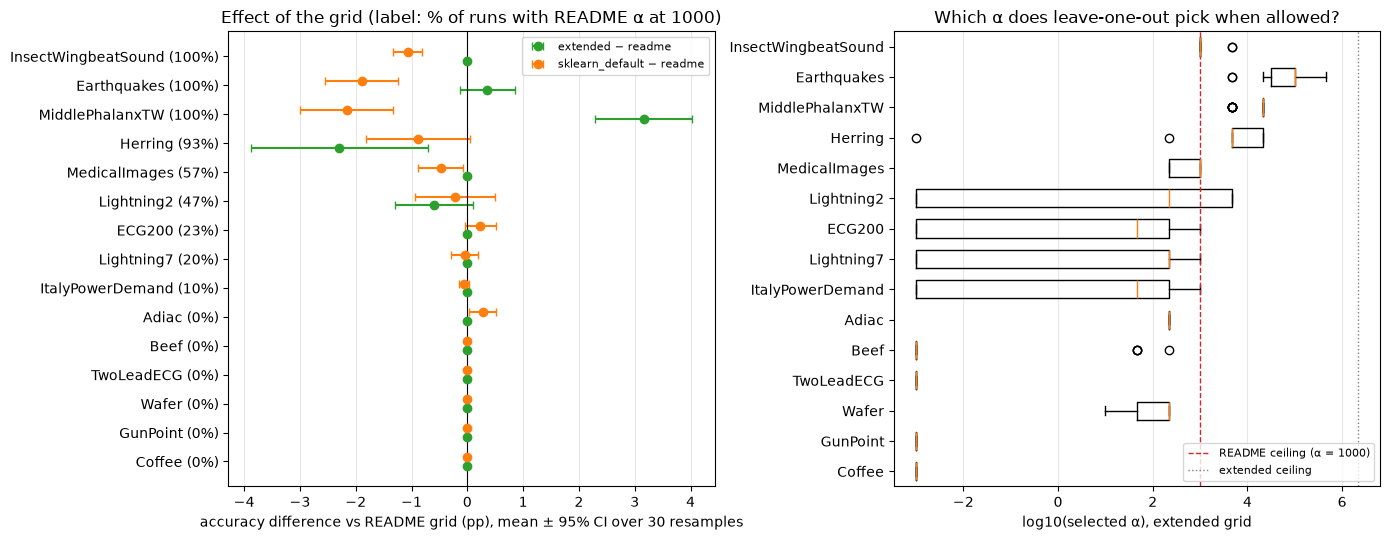

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) paired accuracy difference per dataset, mean with 95% CI over resamples
ax = axes[0]
order = per_dataset.sort_values("% runs readme at 1000").index.tolist()
for j, (other, colour) in enumerate((("extended", "tab:green"), ("sklearn_default", "tab:orange"))):
    diffs = [(acc.loc[d, other] - acc.loc[d, "readme"]) * 100 for d in order]
    means = [x.mean() for x in diffs]
    ci = [1.96 * x.std(ddof=1) / np.sqrt(len(x)) for x in diffs]
    ax.errorbar(means, np.arange(len(order)) + (j - 0.5) * 0.3, xerr=ci, fmt="o", color=colour, capsize=3,
                label=f"{other} − readme")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([f"{d} ({per_dataset.loc[d, '% runs readme at 1000']:.0f}%)" for d in order])
ax.set_xlabel("accuracy difference vs README grid (pp), mean ± 95% CI over 30 resamples")
ax.set_title("Effect of the grid (label: % of runs with README α at 1000)")
ax.grid(True, axis="x", alpha=0.3)
ax.legend(fontsize=8)

# (b) distribution of the selected alpha with the extended grid
ax = axes[1]
ext_alpha = runs[runs.grid == "extended"].pivot(index="resample", columns="dataset", values="ridge_alpha")[order]
ax.boxplot([np.log10(ext_alpha[d]) for d in order], orientation="horizontal", widths=0.6)
ax.axvline(3, color="tab:red", ls="--", lw=1, label="README ceiling (α = 1000)")
ax.axvline(np.log10(GRIDS["extended"].max()), color="tab:gray", ls=":", lw=1, label="extended ceiling")
ax.set_yticks(np.arange(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xlabel("log10(selected α), extended grid")
ax.set_title("Which α does leave-one-out pick when allowed?")
ax.grid(True, axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="lower right")

fig.tight_layout()
fig.savefig(PLOT_DIR / "alpha_grid_effect.png", dpi=200)
plt.show()

### Cell 11 - Save summary

In [11]:
summary = per_dataset.join(vs_paper)
summary.to_csv(OUT_DIR / "alpha_grid_summary.csv")
print("Saved", OUT_DIR / "alpha_grid_summary.csv")

Saved c:\Users\User\Documents\hydra-time-series-project\results\Aarti\alpha_grid\alpha_grid_summary.csv


## Results and interpretation

**Run:** 15 datasets × 30 resamples × 3 grids = 1,350 fits on identical Hydra features.

### 1. The reproduction is exactly reproducible
With the README grid, all **450 / 450 runs give the identical test accuracy** as the runs saved by `aarti_hydra_reproduction_resamples.ipynb` (449 / 450 also select the identical α; the one difference does not change any prediction). Same code, splits and seeds reproduce the earlier results bit-for-bit, on a different laptop and PyTorch version.

### 2. The extended grid is wide enough
| Grid | α at upper edge | α at lower edge |
|---|---:|---:|
| `sklearn_default` (0.1–10) | 63.3 % | 36.7 % |
| `readme` (0.001–1000) | 36.7 % | 36.7 % |
| `extended` (0.001–2.2·10⁶) | **0.0 %** | 36.7 % |

With the extended grid, leave-one-out picks α > 1000 in **22 % of runs** (largest chosen: 4.6·10⁵, below the new ceiling), so the extended grid is no longer a constraint. The lower-edge share is unchanged in every grid: it comes from easy datasets (Coffee, GunPoint, TwoLeadECG) where all α values tie on leave-one-out error and scikit-learn keeps the smallest - a tie-breaking artefact, not a preference for weaker regularisation.

### 3. Removing the ceiling does not improve accuracy on average - but it changes individual datasets
* **Overall:** extended − README = **+0.04 pp** over 15 datasets (2 better / 10 identical / 3 worse, Wilcoxon p = 0.75). No systematic gain.
* **On the 10 datasets where README α was rarely at the ceiling, nothing changes** (identical accuracy on all 30 resamples for 9 of them).
* **On the datasets where README α was at the ceiling, the effect goes both ways:**

| Dataset | README α at 1000 | Extended − README | Resamples better / same / worse | p |
|---|---:|---:|---|---:|
| MiddlePhalanxTW | 100 % | **+3.16 pp** | 27 / 3 / 0 | < 0.001 |
| Earthquakes | 100 % | +0.36 pp | 13 / 6 / 11 | 0.18 |
| InsectWingbeatSound | 100 % | −0.01 pp | 1 / 28 / 1 | 0.99 |
| MedicalImages | 57 % | 0.00 pp | 0 / 30 / 0 | 1.00 |
| Herring | 93 % | **−2.29 pp** | 6 / 6 / 18 | 0.011 |
| Lightning2 | 47 % | −0.60 pp | 2 / 22 / 6 | 0.23 |

Two lessons follow:
1. **Hitting the edge does not always mean the grid is limiting.** On MedicalImages, leave-one-out still picks exactly 1000 when larger values are allowed, so 1000 was the real optimum.
2. **Stronger regularisation chosen by leave-one-out does not reliably generalise.** It helps on MiddlePhalanxTW (399 training cases) but hurts on Herring (only 64 training cases), where the leave-one-out estimate is noisy and picks α values that are too large.

### 4. scikit-learn's default grid is significantly worse
The default `RidgeClassifierCV()` grid (0.1, 1, 10) is at its upper edge in 63 % of runs and loses **−0.42 pp on average** against the README grid (2 better / 4 same / 9 worse, **p = 0.040**), with losses of up to −2.2 pp (MiddlePhalanxTW), −1.9 pp (Earthquakes) and −1.1 pp (InsectWingbeatSound). Results obtained with the default grid therefore understate Hydra's accuracy on harder datasets, and should not be compared directly with results that use the README grid.

### 5. The README grid is the one that matches the paper
Mean |difference to the published accuracies|: **README 0.44 pp**, extended 0.52 pp, scikit-learn default 0.70 pp. The README grid reproduces the paper most closely, supporting the conclusion that the published results were produced with it.

### Summary for the report
The ridge regularisation grid is an **unreported hyperparameter** of Hydra that can move individual datasets by ±3 pp but leaves the average unchanged. The published results correspond to the authors' README grid (`np.logspace(-3, 3, 10)`). Its frequent upper-edge hits are real but mostly harmless: widening the grid helps some datasets and hurts others because leave-one-out α selection is itself noisy on small training sets. A narrower grid (scikit-learn's default) is clearly worse. For reproducibility, papers should report the grid. For comparisons inside a project, every experiment must use the same grid.

### Caveats
* Hydra features only (no MultiRocket or QUANT); 15 datasets.
* α is selected by leave-one-out on the training set, as in the authors' code; other selection methods (e.g. k-fold, nested CV) were not tested.
